In [12]:
import requests

url = "https://api.data.gov.hk/v1/carpark-info-vacancy"
params = {
    "data": "info",
    "lang": "zh_TW"
}

response = requests.get(url, params=params, timeout=30)
print("Status Code:", response.status_code)

if response.status_code == 200:
    data = response.json()
    results = data.get("results", [])
    print("總停車場數量:", len(results))
else:
    print("請求失敗")

Status Code: 200
總停車場數量: 587


In [13]:
# 篩選觀塘區和沙田區
target_districts = ["觀塘區", "沙田區"]
filtered = [cp for cp in results if cp.get("district") in target_districts]

print(f"觀塘區 + 沙田區 停車場數量: {len(filtered)}")

# 顯示前 5 個
for i, cp in enumerate(filtered[:5]):
    print(f"{i+1}. {cp.get('name')} ({cp.get('district')})")

觀塘區 + 沙田區 停車場數量: 150
1. 淘大商場 (觀塘區)
2. 油麗商場停車場 (觀塘區)
3. 德福廣場D車場 (觀塘區)
4. 德福廣場一期停車場 (觀塘區)
5. 德福廣場二期停車場 (觀塘區)


In [14]:
import pandas as pd

# 提取關鍵欄位
records = []
for cp in filtered:
    records.append({
        "park_id": cp.get("park_Id"),
        "name": cp.get("name"),
        "district": cp.get("district"),
        "latitude": cp.get("latitude"),
        "longitude": cp.get("longitude"),
        "address": cp.get("displayAddress")
    })

df = pd.DataFrame(records)
df.to_csv("carparks_kwuntong_shatin.csv", index=False, encoding="utf-8-sig")
print("已儲存，總共", len(df), "筆")
print(df.head())

已儲存，總共 150 筆
  park_id       name district   latitude   longitude                 address
0      12       淘大商場      觀塘區  22.324701  114.216753            九龍九龍灣牛頭角道77號
1      27    油麗商場停車場      觀塘區  22.298512  114.237401  九龍油塘油塘道9號油麗商場LG1 & LG2
2      30    德福廣場D車場      觀塘區  22.322289  114.212043             九龍九龍灣偉業街33號
3      31  德福廣場一期停車場      觀塘區  22.322686  114.213535             九龍九龍灣偉業街33號
4      32  德福廣場二期停車場      觀塘區  22.321356  114.213266             九龍九龍灣偉業街33號


In [15]:
import json

# 取得空位數據
params_vacancy = {
    "data": "vacancy",
    "lang": "zh_TW",
    "vehicleTypes": "privateCar"
}

response_v = requests.get(url, params=params_vacancy, timeout=30)
print("Status Code:", response_v.status_code)

if response_v.status_code == 200:
    vacancy_data = response_v.json()
    vacancy_results = vacancy_data.get("results", [])
    print("空位數據總筆數:", len(vacancy_results))
    
    # 顯示前 2 筆的結構
    if vacancy_results:
        print(json.dumps(vacancy_results[0], ensure_ascii=False, indent=2)[:800])
else:
    print("請求失敗")

Status Code: 200
空位數據總筆數: 574
{
  "park_Id": "12",
  "privateCar": [
    {
      "vacancy_type": "A",
      "vacancyEV": 1,
      "vacancyDIS": 1,
      "vacancy": 13,
      "lastupdate": "2026-10-17 18:32:45"
    }
  ],
  "LGV": [
    {
      "vacancy_type": "A",
      "vacancy": 0,
      "lastupdate": "2026-10-17 18:32:45"
    }
  ],
  "HGV": [
    {
      "vacancy_type": "A",
      "vacancy": 0,
      "lastupdate": "2026-10-17 18:32:45"
    }
  ],
  "motorCycle": [
    {
      "vacancy_type": "A",
      "vacancy": 0,
      "lastupdate": "2026-10-17 18:32:45"
    }
  ]
}


In [16]:
# 建立 park_id 對應表（只保留我們關心的）
target_ids = set(df["park_id"].astype(str))

# 提取私家車空位
vacancy_records = []
for item in vacancy_results:
    park_id = str(item.get("park_Id"))
    if park_id not in target_ids:
        continue
    
    private = item.get("privateCar", [])
    if private:
        v = private[0]
        vacancy_records.append({
            "park_id": park_id,
            "vacancy": v.get("vacancy"),
            "vacancy_type": v.get("vacancy_type"),
            "lastupdate": v.get("lastupdate")
        })

vacancy_df = pd.DataFrame(vacancy_records)
print("成功對應的停車場數量:", len(vacancy_df))
print(vacancy_df.head(10))

成功對應的停車場數量: 149
  park_id  vacancy vacancy_type           lastupdate
0      12       13            A  2026-10-17 18:32:45
1      27        4            A  2026-10-18 22:02:20
2      30       62            A  2026-10-18 22:05:20
3      31       92            A  2026-10-18 22:23:10
4      32       68            A  2026-10-18 22:19:00
5      37       45            A  2026-10-18 21:26:51
6      38      126            A  2026-10-18 22:02:17
7      39        0            A  2026-10-18 21:59:00
8      75       50            A  2026-10-18 22:26:16
9      77       97            A  2026-10-18 22:09:30


In [17]:
# 找出缺少的 park_id
matched_ids = set(vacancy_df["park_id"].astype(str))
all_ids = set(df["park_id"].astype(str))

missing_ids = all_ids - matched_ids
print("缺少的 park_id:", missing_ids)

# 顯示該停車場的基本資訊
if missing_ids:
    missing_info = df[df["park_id"].astype(str).isin(missing_ids)]
    print(missing_info)

缺少的 park_id: {'129'}
   park_id        name district   latitude   longitude  \
19     129  THE CENDAS      觀塘區  22.322051  114.209876   

                        address  
19  九龍九龍灣常悅道15號THE CENDASG/F管理處  


In [18]:
# 再次取得空位數據，檢查 129 是否存在
response_v2 = requests.get(url, params=params_vacancy, timeout=30)
vacancy_results2 = response_v2.json().get("results", [])

found_129 = any(str(item.get("park_Id")) == "129" for item in vacancy_results2)
print("park_id 129 是否出現在空位數據中:", found_129)

park_id 129 是否出現在空位數據中: False


In [19]:
import sqlite3

conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS vacancy_records (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    park_id TEXT,
    vacancy INTEGER,
    vacancy_type TEXT,
    lastupdate TEXT,
    collected_at TEXT
)
""")

conn.commit()
print("資料庫 parking.db 已建立")
conn.close()

資料庫 parking.db 已建立


In [20]:
from datetime import datetime
import sqlite3

conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

collected_at = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# 寫入 vacancy_df 的數據
for _, row in vacancy_df.iterrows():
    cursor.execute("""
        INSERT INTO vacancy_records (park_id, vacancy, vacancy_type, lastupdate, collected_at)
        VALUES (?, ?, ?, ?, ?)
    """, (row["park_id"], row["vacancy"], row["vacancy_type"], row["lastupdate"], collected_at))

conn.commit()
print(f"已寫入 {len(vacancy_df)} 筆資料")

# 確認寫入結果
cursor.execute("SELECT COUNT(*) FROM vacancy_records")
print("資料庫目前總筆數:", cursor.fetchone()[0])

conn.close()

已寫入 149 筆資料
資料庫目前總筆數: 149


In [21]:
from datetime import datetime
import sqlite3
import requests
import pandas as pd

def collect_vacancy():
    url = "https://api.data.gov.hk/v1/carpark-info-vacancy"
    params = {
        "data": "vacancy",
        "lang": "zh_TW",
        "vehicleTypes": "privateCar"
    }
    
    response = requests.get(url, params=params, timeout=30)
    if response.status_code != 200:
        print("請求失敗")
        return
    
    vacancy_results = response.json().get("results", [])
    target_ids = set(df["park_id"].astype(str))  # 使用之前的 df
    
    records = []
    for item in vacancy_results:
        park_id = str(item.get("park_Id"))
        if park_id not in target_ids:
            continue
        private = item.get("privateCar", [])
        if private:
            v = private[0]
            records.append({
                "park_id": park_id,
                "vacancy": v.get("vacancy"),
                "vacancy_type": v.get("vacancy_type"),
                "lastupdate": v.get("lastupdate")
            })
    
    if not records:
        print("沒有新資料")
        return
    
    collected_at = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    conn = sqlite3.connect("parking.db")
    cursor = conn.cursor()
    
    for r in records:
        cursor.execute("""
            INSERT INTO vacancy_records (park_id, vacancy, vacancy_type, lastupdate, collected_at)
            VALUES (?, ?, ?, ?, ?)
        """, (r["park_id"], r["vacancy"], r["vacancy_type"], r["lastupdate"], collected_at))
    
    conn.commit()
    conn.close()
    print(f"成功收集並寫入 {len(records)} 筆資料 ({collected_at})")

# 測試執行一次
collect_vacancy()

成功收集並寫入 149 筆資料 (2026-10-18 22:58:16)


In [22]:
conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM vacancy_records")
print("資料庫總筆數:", cursor.fetchone()[0])

cursor.execute("""
    SELECT park_id, vacancy, collected_at 
    FROM vacancy_records 
    ORDER BY id DESC 
    LIMIT 5
""")
print("\n最新 5 筆:")
for row in cursor.fetchall():
    print(row)

conn.close()

資料庫總筆數: 298

最新 5 筆:
('tdc415p1', 99, '2026-10-18 22:58:16')
('tdc416p1', 99, '2026-10-18 22:58:16')
('tdc417p1', 64, '2026-10-18 22:58:16')
('tdc154p1', 15, '2026-10-18 22:58:16')
('tdc16p575', 10, '2026-10-18 22:58:16')


In [23]:
import time

print("開始測試收集 3 次...")
for i in range(3):
    print(f"\n第 {i+1} 次收集")
    collect_vacancy()
    if i < 2:
        time.sleep(10)  # 等待 10 秒

print("\n測試完成")

開始測試收集 3 次...

第 1 次收集
成功收集並寫入 149 筆資料 (2026-10-18 23:05:16)

第 2 次收集
成功收集並寫入 149 筆資料 (2026-10-18 23:05:26)

第 3 次收集
成功收集並寫入 149 筆資料 (2026-10-18 23:05:37)

測試完成


In [24]:
conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM vacancy_records")
print("目前總筆數:", cursor.fetchone()[0])

cursor.execute("SELECT COUNT(DISTINCT collected_at) FROM vacancy_records")
print("已收集的時間點數量:", cursor.fetchone()[0])

conn.close()

目前總筆數: 745
已收集的時間點數量: 5


In [25]:
conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

# 建立停車場基本資訊表
cursor.execute("""
CREATE TABLE IF NOT EXISTS carparks (
    park_id TEXT PRIMARY KEY,
    name TEXT,
    district TEXT,
    latitude REAL,
    longitude REAL,
    address TEXT
)
""")

# 寫入數據
for _, row in df.iterrows():
    cursor.execute("""
        INSERT OR REPLACE INTO carparks (park_id, name, district, latitude, longitude, address)
        VALUES (?, ?, ?, ?, ?, ?)
    """, (str(row["park_id"]), row["name"], row["district"], 
          row["latitude"], row["longitude"], row["address"]))

conn.commit()
print("已寫入停車場基本資訊")

cursor.execute("SELECT COUNT(*) FROM carparks")
print("carparks 表筆數:", cursor.fetchone()[0])

conn.close()

已寫入停車場基本資訊
carparks 表筆數: 150


In [26]:
conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM vacancy_records")
print("目前總筆數:", cursor.fetchone()[0])

cursor.execute("SELECT COUNT(DISTINCT collected_at) FROM vacancy_records")
print("已收集的時間點數量:", cursor.fetchone()[0])

cursor.execute("""
    SELECT MIN(collected_at), MAX(collected_at) 
    FROM vacancy_records
""")
print("收集時間範圍:", cursor.fetchone())

conn.close()

目前總筆數: 1192
已收集的時間點數量: 8
收集時間範圍: ('2026-10-18 22:57:22', '2026-10-18 23:31:04')


In [27]:
conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM vacancy_records")
print("目前總筆數:", cursor.fetchone()[0])

cursor.execute("SELECT COUNT(DISTINCT collected_at) FROM vacancy_records")
print("已收集的時間點數量:", cursor.fetchone()[0])

cursor.execute("""
    SELECT MIN(collected_at), MAX(collected_at) 
    FROM vacancy_records
""")
print("收集時間範圍:", cursor.fetchone())

conn.close()

目前總筆數: 2086
已收集的時間點數量: 14
收集時間範圍: ('2026-10-18 22:57:22', '2026-10-19 15:08:24')


In [28]:
conn = sqlite3.connect("parking.db")

query = """
SELECT park_id, vacancy, collected_at
FROM vacancy_records
WHERE park_id IN ('12', '30', '31')
ORDER BY park_id, collected_at
"""

df_sample = pd.read_sql_query(query, conn)
print(df_sample)

conn.close()

   park_id  vacancy         collected_at
0       12       13  2026-10-18 22:57:22
1       12       13  2026-10-18 22:58:16
2       12       13  2026-10-18 23:05:16
3       12       13  2026-10-18 23:05:26
4       12       13  2026-10-18 23:05:37
5       12       13  2026-10-18 23:11:01
6       12       13  2026-10-18 23:21:03
7       12       13  2026-10-18 23:31:04
8       12       13  2026-10-19 09:36:19
9       12       13  2026-10-19 14:22:09
10      12       13  2026-10-19 14:32:11
11      12       13  2026-10-19 14:42:12
12      12       13  2026-10-19 14:52:13
13      12       13  2026-10-19 15:08:24
14      30       62  2026-10-18 22:57:22
15      30       64  2026-10-18 22:58:16
16      30       64  2026-10-18 23:05:16
17      30       64  2026-10-18 23:05:26
18      30       64  2026-10-18 23:05:37
19      30       64  2026-10-18 23:11:01
20      30       64  2026-10-18 23:21:03
21      30       65  2026-10-18 23:31:04
22      30       60  2026-10-19 09:36:19
23      30      

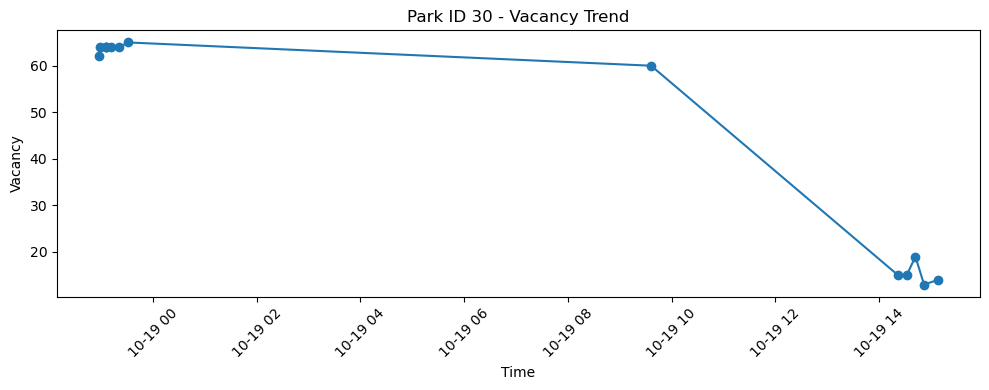

In [29]:
import matplotlib.pyplot as plt

# 只取 park_id = 30 的數據
df_30 = df_sample[df_sample["park_id"] == "30"].copy()
df_30["collected_at"] = pd.to_datetime(df_30["collected_at"])

plt.figure(figsize=(10, 4))
plt.plot(df_30["collected_at"], df_30["vacancy"], marker="o")
plt.title("Park ID 30 - Vacancy Trend")
plt.xlabel("Time")
plt.ylabel("Vacancy")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
conn = sqlite3.connect("parking.db")

query = """
SELECT collected_at, AVG(vacancy) as avg_vacancy, COUNT(*) as num_carparks
FROM vacancy_records
GROUP BY collected_at
ORDER BY collected_at
"""

df_avg = pd.read_sql_query(query, conn)
df_avg["collected_at"] = pd.to_datetime(df_avg["collected_at"])
print(df_avg)

conn.close()

          collected_at  avg_vacancy  num_carparks
0  2026-10-18 22:57:22    35.093960           149
1  2026-10-18 22:58:16    34.489933           149
2  2026-10-18 23:05:16    34.932886           149
3  2026-10-18 23:05:26    34.926174           149
4  2026-10-18 23:05:37    34.932886           149
5  2026-10-18 23:11:01    34.637584           149
6  2026-10-18 23:21:03    35.389262           149
7  2026-10-18 23:31:04    35.630872           149
8  2026-10-19 09:36:19    33.100671           149
9  2026-10-19 14:22:09    23.677852           149
10 2026-10-19 14:32:11    25.147651           149
11 2026-10-19 14:42:12    25.711409           149
12 2026-10-19 14:52:13    25.281879           149
13 2026-10-19 15:08:24    24.496644           149


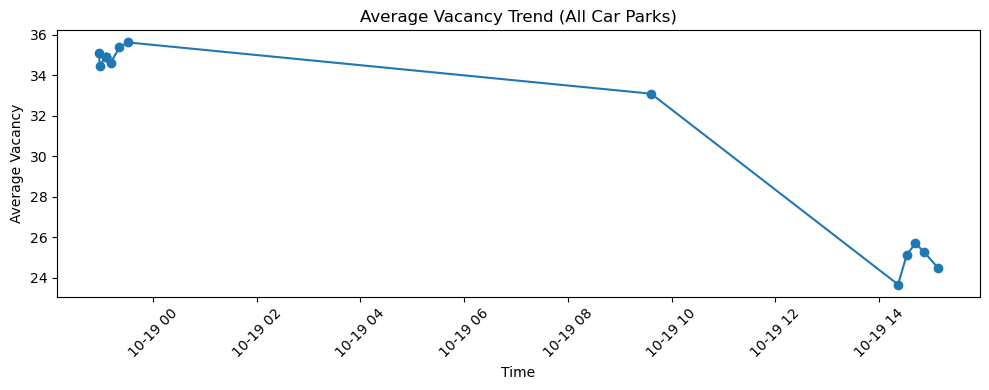

In [31]:
plt.figure(figsize=(10, 4))
plt.plot(df_avg["collected_at"], df_avg["avg_vacancy"], marker="o")
plt.title("Average Vacancy Trend (All Car Parks)")
plt.xlabel("Time")
plt.ylabel("Average Vacancy")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
weather_url = "https://data.weather.gov.hk/weatherAPI/opendata/weather.php"
weather_params = {
    "dataType": "rhrread",
    "lang": "tc"
}

weather_response = requests.get(weather_url, params=weather_params, timeout=30)
print("Status Code:", weather_response.status_code)

if weather_response.status_code == 200:
    weather_data = weather_response.json()
    print("更新時間:", weather_data.get("updateTime"))
    # 顯示溫度與降雨簡要
    temp = weather_data.get("temperature", {}).get("data", [])
    print("部分溫度數據:", temp[:2] if temp else "無")
else:
    print("請求失敗")

Status Code: 200
更新時間: 2026-10-19T15:02:00+08:00
部分溫度數據: [{'place': '京士柏', 'value': 31, 'unit': 'C'}, {'place': '香港天文台', 'value': 32, 'unit': 'C'}]


In [33]:
rainfall = weather_data.get("rainfall", {}).get("data", [])
print("降雨數據筆數:", len(rainfall))

# 顯示前 5 個地區的降雨
for item in rainfall[:5]:
    print(f"{item.get('place')}: {item.get('max')} mm")

降雨數據筆數: 18
中西區: 0 mm
東區: 0 mm
葵青: 0 mm
離島區: 0 mm
北區: 0 mm


In [34]:
conn = sqlite3.connect("parking.db")

query = """
SELECT park_id, vacancy, collected_at
FROM vacancy_records
ORDER BY collected_at
LIMIT 20
"""

df_time = pd.read_sql_query(query, conn)
df_time["collected_at"] = pd.to_datetime(df_time["collected_at"])

# 提取時間特徵
df_time["hour"] = df_time["collected_at"].dt.hour
df_time["dayofweek"] = df_time["collected_at"].dt.dayofweek  # 0=星期一
df_time["is_weekend"] = df_time["dayofweek"].isin([5, 6]).astype(int)

print(df_time[["park_id", "vacancy", "collected_at", "hour", "dayofweek", "is_weekend"]].head(10))

conn.close()

  park_id  vacancy        collected_at  hour  dayofweek  is_weekend
0      12       13 2026-10-18 22:57:22    22          6           1
1      27        4 2026-10-18 22:57:22    22          6           1
2      30       62 2026-10-18 22:57:22    22          6           1
3      31       92 2026-10-18 22:57:22    22          6           1
4      32       68 2026-10-18 22:57:22    22          6           1
5      37       45 2026-10-18 22:57:22    22          6           1
6      38      126 2026-10-18 22:57:22    22          6           1
7      39        0 2026-10-18 22:57:22    22          6           1
8      75       50 2026-10-18 22:57:22    22          6           1
9      77       97 2026-10-18 22:57:22    22          6           1


In [35]:
# 讀取所有數據並提取時間特徵
conn = sqlite3.connect("parking.db")
df_all = pd.read_sql_query("SELECT * FROM vacancy_records", conn)
conn.close()

df_all["collected_at"] = pd.to_datetime(df_all["collected_at"])
df_all["hour"] = df_all["collected_at"].dt.hour
df_all["dow"] = df_all["collected_at"].dt.dayofweek  # 0=Monday

# 計算每個 park_id + hour + dow 的平均空位（作為 baseline）
baseline = df_all.groupby(["park_id", "hour", "dow"])["vacancy"].mean().reset_index()
baseline.columns = ["park_id", "hour", "dow", "baseline_vacancy"]

# 合併回原數據
df_merged = df_all.merge(baseline, on=["park_id", "hour", "dow"], how="left")

# 計算 MAE
mae = (df_merged["vacancy"] - df_merged["baseline_vacancy"]).abs().mean()
print(f"目前 Baseline MAE: {mae:.2f}")
print(f"數據筆數: {len(df_merged)}")

目前 Baseline MAE: 0.68
數據筆數: 2831


In [36]:
# 按時間排序
df_all = df_all.sort_values("collected_at")

# 用前 70% 數據計算 baseline，後 30% 做測試
split_idx = int(len(df_all) * 0.7)
train = df_all.iloc[:split_idx]
test = df_all.iloc[split_idx:]

# 用訓練集計算 baseline
baseline_train = train.groupby(["park_id", "hour", "dow"])["vacancy"].mean().reset_index()
baseline_train.columns = ["park_id", "hour", "dow", "baseline_vacancy"]

# 在測試集上評估
test_merged = test.merge(baseline_train, on=["park_id", "hour", "dow"], how="left")
test_merged["baseline_vacancy"] = test_merged["baseline_vacancy"].fillna(test_merged["vacancy"].mean())

mae_test = (test_merged["vacancy"] - test_merged["baseline_vacancy"]).abs().mean()
print(f"測試集 Baseline MAE: {mae_test:.2f}")
print(f"測試集筆數: {len(test_merged)}")

測試集 Baseline MAE: 17.84
測試集筆數: 850


In [37]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

# 準備特徵
features = ["hour", "dow"]
X_train = train[features]
y_train = train["vacancy"]
X_test = test[features]
y_test = test["vacancy"]

# 訓練模型
model = GradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)

# 預測並計算 MAE
y_pred = model.predict(X_test)
mae_model = mean_absolute_error(y_test, y_pred)
print(f"模型 MAE: {mae_model:.2f}")
print(f"Baseline MAE: {mae_test:.2f}")
print(f"改善幅度: {mae_test - mae_model:.2f}")

模型 MAE: 21.42
Baseline MAE: 17.84
改善幅度: -3.58


In [38]:
# 把 park_id 轉成數值特徵（簡單做法：用 category code）
train["park_code"] = train["park_id"].astype("category").cat.codes
test["park_code"] = test["park_id"].astype("category").cat.codes

features = ["hour", "dow", "park_code"]
X_train = train[features]
y_train = train["vacancy"]
X_test = test[features]
y_test = test["vacancy"]

model = GradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
mae_model = mean_absolute_error(y_test, y_pred)
print(f"模型 MAE: {mae_model:.2f}")
print(f"Baseline MAE: {mae_test:.2f}")
print(f"改善幅度: {mae_test - mae_model:.2f}")

模型 MAE: 10.80
Baseline MAE: 17.84
改善幅度: 7.03


/var/folders/ct/chbp26vx6hbc26zt3mtv_9p40000gn/T/ipykernel_34823/4267598122.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train["park_code"] = train["park_id"].astype("category").cat.codes
/var/folders/ct/chbp26vx6hbc26zt3mtv_9p40000gn/T/ipykernel_34823/4267598122.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test["park_code"] = test["park_id"].astype("category").cat.codes


In [39]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import f1_score, classification_report

# 建立分類目標：vacancy > 0 為有位 (1)，否則為 0
train["has_vacancy"] = (train["vacancy"] > 0).astype(int)
test["has_vacancy"] = (test["vacancy"] > 0).astype(int)

features = ["hour", "dow", "park_code"]
X_train = train[features]
y_train_cls = train["has_vacancy"]
X_test = test[features]
y_test_cls = test["has_vacancy"]

clf = GradientBoostingClassifier(random_state=42)
clf.fit(X_train, y_train_cls)

y_pred_cls = clf.predict(X_test)
print("F1 Score:", f1_score(y_test_cls, y_pred_cls))
print("\nClassification Report:")
print(classification_report(y_test_cls, y_pred_cls))

F1 Score: 0.9573863636363636

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.66      0.79       176
           1       0.92      1.00      0.96       674

    accuracy                           0.93       850
   macro avg       0.96      0.83      0.88       850
weighted avg       0.94      0.93      0.92       850



/var/folders/ct/chbp26vx6hbc26zt3mtv_9p40000gn/T/ipykernel_34823/2992189545.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train["has_vacancy"] = (train["vacancy"] > 0).astype(int)
/var/folders/ct/chbp26vx6hbc26zt3mtv_9p40000gn/T/ipykernel_34823/2992189545.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test["has_vacancy"] = (test["vacancy"] > 0).astype(int)


In [40]:
# 取得天氣數據
weather_url = "https://data.weather.gov.hk/weatherAPI/opendata/weather.php"
weather_params = {"dataType": "rhrread", "lang": "en"}

resp = requests.get(weather_url, params=weather_params, timeout=30)
weather = resp.json()

# 提取香港天文台溫度與整體降雨
hko_temp = None
for t in weather.get("temperature", {}).get("data", []):
    if t.get("place") == "Hong Kong Observatory":
        hko_temp = t.get("value")
        break

rainfall_data = weather.get("rainfall", {}).get("data", [])
max_rainfall = max([r.get("max", 0) for r in rainfall_data]) if rainfall_data else 0

print("香港天文台溫度:", hko_temp)
print("最高地區降雨:", max_rainfall, "mm")
print("更新時間:", weather.get("updateTime"))

香港天文台溫度: 31
最高地區降雨: 0 mm
更新時間: 2026-10-19T16:02:00+08:00


In [41]:
def predict_vacancy(park_id, hour, dow):
    """簡單預測函數（使用剛才訓練的模型）"""
    # 需要先確保 park_code 的對應關係
    park_codes = dict(zip(train["park_id"], train["park_code"]))
    park_code = park_codes.get(park_id, 0)
    
    X = pd.DataFrame([[hour, dow, park_code]], columns=["hour", "dow", "park_code"])
    pred = model.predict(X)[0]
    return max(0, round(pred))  # 空位不能為負

# 測試預測
print("預測 park_id 30，下午 3 點（週一）空位數:", predict_vacancy("30", 15, 0))
print("預測 park_id 12，晚上 10 點（週日）空位數:", predict_vacancy("12", 22, 6))

預測 park_id 30，下午 3 點（週一）空位數: 34
預測 park_id 12，晚上 10 點（週日）空位數: 20


In [42]:
def generate_suggestion(park_id, hour, dow, predicted_vacancy):
    """生成簡單建議文字"""
    # 取得停車場名稱
    park_name = df[df["park_id"] == park_id]["name"].values
    name = park_name[0] if len(park_name) > 0 else park_id
    
    if predicted_vacancy > 20:
        status = "較易找到空位"
    elif predicted_vacancy > 5:
        status = "可能有少量空位"
    else:
        status = "可能較難找到空位"
    
    return f"{name} 在大約 {hour}:00 預計有 {predicted_vacancy} 個空位，{status}。"

# 測試
print(generate_suggestion("30", 15, 0, 34))
print(generate_suggestion("12", 22, 6, 20))

德福廣場D車場 在大約 15:00 預計有 34 個空位，較易找到空位。
淘大商場 在大約 22:00 預計有 20 個空位，可能有少量空位。


In [43]:
def find_easier_parking(hour=19, dow=0, top_n=5):
    """找出指定時間較易泊車的停車場"""
    results = []
    for park_id in df["park_id"].astype(str).unique()[:50]:  # 先測試前 50 個
        pred = predict_vacancy(park_id, hour, dow)
        name = df[df["park_id"].astype(str) == park_id]["name"].values
        name = name[0] if len(name) > 0 else park_id
        results.append({"name": name, "park_id": park_id, "predicted_vacancy": pred})
    
    results_df = pd.DataFrame(results).sort_values("predicted_vacancy", ascending=False)
    return results_df.head(top_n)

# 測試：今晚 7 點（假設週一）
print(find_easier_parking(hour=19, dow=0, top_n=5))

            name park_id  predicted_vacancy
12  油塘仁宇圍8號公眾停車場      88                 95
6         大本型停車場      38                 73
10            綠景      79                 67
9        金利豐國際中心      77                 67
11          宏利廣場      81                 67


In [44]:
def find_easier_parking_v2(hour=19, dow=0, top_n=5):
    """找出指定時間較易泊車的停車場（含地區）"""
    results = []
    for park_id in df["park_id"].astype(str).unique():
        pred = predict_vacancy(park_id, hour, dow)
        info = df[df["park_id"].astype(str) == park_id]
        name = info["name"].values[0] if len(info) > 0 else park_id
        district = info["district"].values[0] if len(info) > 0 else ""
        results.append({
            "name": name, 
            "district": district,
            "park_id": park_id, 
            "predicted_vacancy": pred
        })
    
    results_df = pd.DataFrame(results).sort_values("predicted_vacancy", ascending=False)
    return results_df.head(top_n)

print(find_easier_parking_v2(hour=19, dow=0, top_n=5))

              name district   park_id  predicted_vacancy
108      科學園停車場 P2      沙田區  tdc103p2                302
107      科學園停車場 P1      沙田區  tdc103p1                255
65             鞍駿街      沙田區   tdstt11                141
144  The ANGLE 停車場      觀塘區  tdc336p1                115
84         金利豐國際中心      觀塘區  tdc108p1                102


/var/folders/ct/chbp26vx6hbc26zt3mtv_9p40000gn/T/ipykernel_34823/515214945.py:8: UserWarning: Glyph 31185 (\N{CJK UNIFIED IDEOGRAPH-79D1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/ct/chbp26vx6hbc26zt3mtv_9p40000gn/T/ipykernel_34823/515214945.py:8: UserWarning: Glyph 23416 (\N{CJK UNIFIED IDEOGRAPH-5B78}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/ct/chbp26vx6hbc26zt3mtv_9p40000gn/T/ipykernel_34823/515214945.py:8: UserWarning: Glyph 22290 (\N{CJK UNIFIED IDEOGRAPH-5712}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/ct/chbp26vx6hbc26zt3mtv_9p40000gn/T/ipykernel_34823/515214945.py:8: UserWarning: Glyph 20572 (\N{CJK UNIFIED IDEOGRAPH-505C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/ct/chbp26vx6hbc26zt3mtv_9p40000gn/T/ipykernel_34823/515214945.py:8: UserWarning: Glyph 36554 (\N{CJK UNIFIED IDEOGRAPH-8ECA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/ct/chbp26vx6hbc26

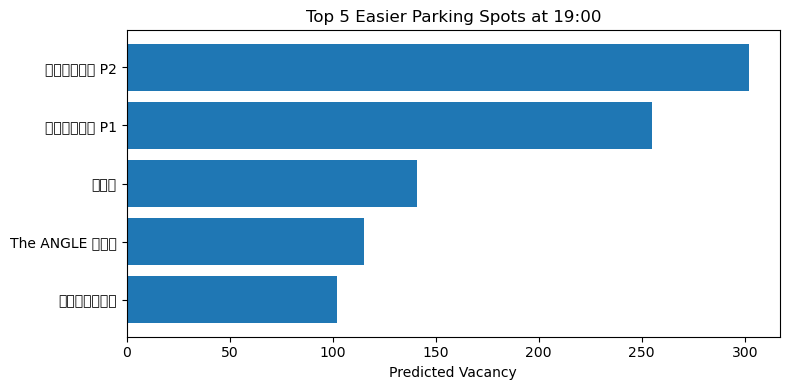

In [45]:
top5 = find_easier_parking_v2(hour=19, dow=0, top_n=5)

plt.figure(figsize=(8, 4))
plt.barh(top5["name"], top5["predicted_vacancy"])
plt.xlabel("Predicted Vacancy")
plt.title("Top 5 Easier Parking Spots at 19:00")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

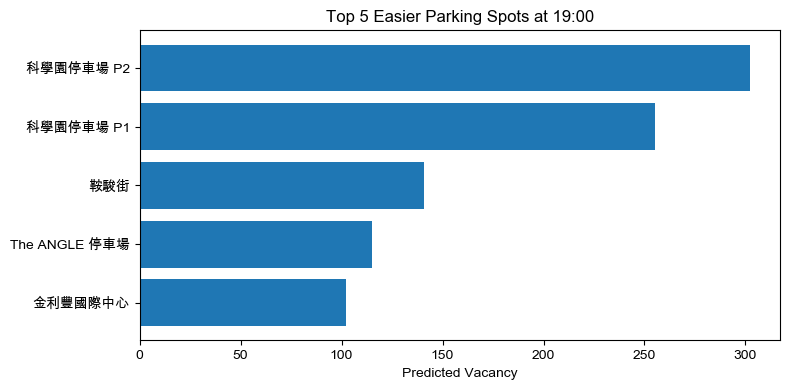

In [46]:
import matplotlib
matplotlib.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang HK', 'Heiti TC', 'SimHei']
matplotlib.rcParams['axes.unicode_minus'] = False

# 重新畫圖
top5 = find_easier_parking_v2(hour=19, dow=0, top_n=5)

plt.figure(figsize=(8, 4))
plt.barh(top5["name"], top5["predicted_vacancy"])
plt.xlabel("Predicted Vacancy")
plt.title("Top 5 Easier Parking Spots at 19:00")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [47]:
conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM vacancy_records")
print("目前總筆數:", cursor.fetchone()[0])

cursor.execute("SELECT COUNT(DISTINCT DATE(collected_at)) FROM vacancy_records")
print("已收集的天數:", cursor.fetchone()[0])

cursor.execute("SELECT MIN(collected_at), MAX(collected_at) FROM vacancy_records")
print("時間範圍:", cursor.fetchone())

conn.close()

目前總筆數: 3129
已收集的天數: 2
時間範圍: ('2026-10-18 22:57:22', '2026-10-19 16:44:23')


In [48]:
# 建立完整特徵 DataFrame
conn = sqlite3.connect("parking.db")
df_full = pd.read_sql_query("""
    SELECT v.park_id, v.vacancy, v.collected_at, c.district, c.name
    FROM vacancy_records v
    LEFT JOIN carparks c ON v.park_id = c.park_id
""", conn)
conn.close()

df_full["collected_at"] = pd.to_datetime(df_full["collected_at"])
df_full["hour"] = df_full["collected_at"].dt.hour
df_full["dow"] = df_full["collected_at"].dt.dayofweek
df_full["is_weekend"] = df_full["dow"].isin([5, 6]).astype(int)
df_full["has_vacancy"] = (df_full["vacancy"] > 0).astype(int)

print("特徵表形狀:", df_full.shape)
print(df_full[["park_id", "name", "district", "hour", "dow", "vacancy", "has_vacancy"]].head())

特徵表形狀: (3129, 9)
  park_id       name district  hour  dow  vacancy  has_vacancy
0      12       淘大商場      觀塘區    22    6       13            1
1      27    油麗商場停車場      觀塘區    22    6        4            1
2      30    德福廣場D車場      觀塘區    22    6       62            1
3      31  德福廣場一期停車場      觀塘區    22    6       92            1
4      32  德福廣場二期停車場      觀塘區    22    6       68            1


In [49]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 時間排序後分割（避免資料洩漏）
df_full = df_full.sort_values("collected_at")
split_idx = int(len(df_full) * 0.7)
train_df = df_full.iloc[:split_idx].copy()
test_df = df_full.iloc[split_idx:].copy()

# 編碼 park_id 和 district
le_park = LabelEncoder()
le_district = LabelEncoder()
train_df["park_code"] = le_park.fit_transform(train_df["park_id"])
test_df["park_code"] = le_park.transform(test_df["park_id"])
train_df["district_code"] = le_district.fit_transform(train_df["district"])
test_df["district_code"] = le_district.transform(test_df["district"])

features = ["hour", "dow", "is_weekend", "park_code", "district_code"]
X_train = train_df[features]
y_train = train_df["vacancy"]
X_test = test_df[features]
y_test = test_df["vacancy"]

model = GradientBoostingRegressor(random_state=42, n_estimators=100)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
print(f"測試集 MAE: {mae:.2f}")
print(f"訓練筆數: {len(train_df)}, 測試筆數: {len(test_df)}")

測試集 MAE: 10.73
訓練筆數: 2190, 測試筆數: 939


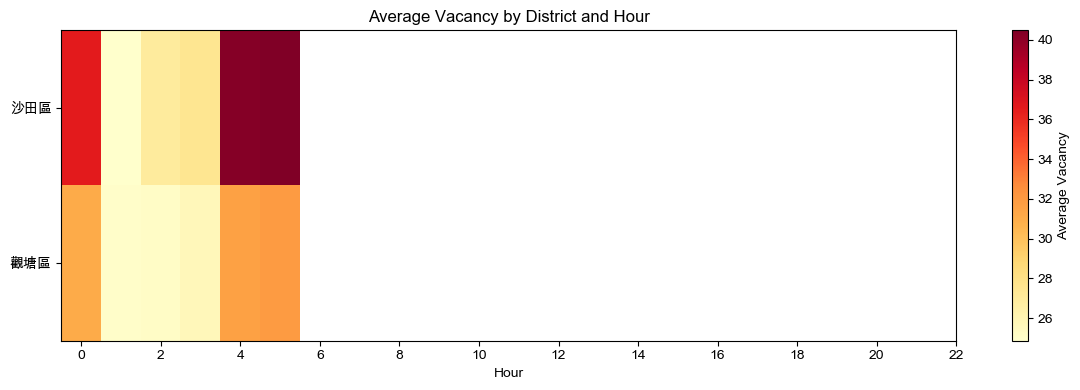

hour        9     14    15    16    22    23
district                                    
沙田區       36.6  24.9  27.0  27.5  40.3  40.5
觀塘區       31.1  25.0  25.1  25.7  31.6  31.9


In [50]:
# 按地區與小時計算平均空位
district_hour = df_full.groupby(["district", "hour"])["vacancy"].mean().reset_index()

# 畫出熱力圖
pivot = district_hour.pivot(index="district", columns="hour", values="vacancy")

plt.figure(figsize=(12, 4))
plt.imshow(pivot, aspect="auto", cmap="YlOrRd")
plt.colorbar(label="Average Vacancy")
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xticks(range(0, 24, 2))
plt.xlabel("Hour")
plt.title("Average Vacancy by District and Hour")
plt.tight_layout()
plt.show()

print(pivot.round(1))